In [ ]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats
from itertools import combinations
from typing import List, Tuple, Optional

In [ ]:
# load dfs
# lysis_optimization_1125
# don't include because of non-relevant testing parameters
act_norm_1125 = pd.read_parquet('act_norm_1125.parquet')

# lysis_check_0126
# group 3, ends in 3 columns
act_norm_0126 = pd.read_parquet('act_norm_0126.parquet')

# lysis_040226
# group 3, ends in 8 columns
act_norm_040226 = pd.read_parquet('act_norm_040226.parquet')

# last_lysis_check_110226
# group 3 then 3, ends in 3 columns
act_norm_110226 = pd.read_parquet('act_norm_110226.parquet')

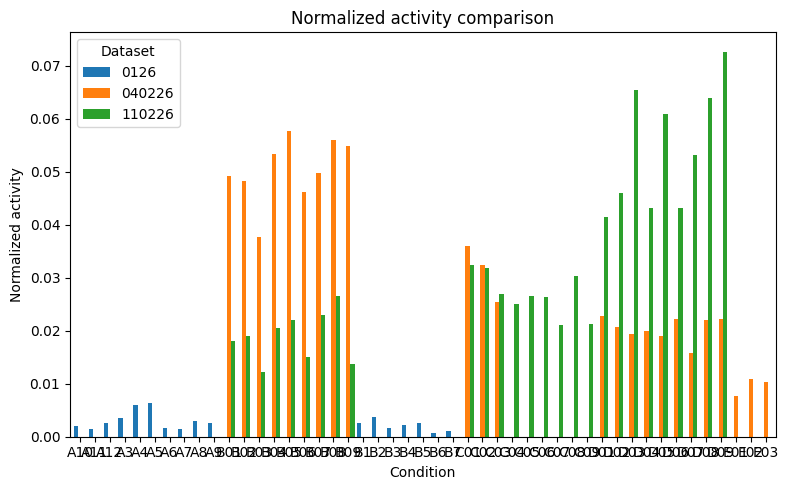

In [ ]:
# quick overview plot
df = pd.DataFrame({
    #"1125": act_norm_1125['mean'],   # <-- select mean column
    "0126": act_norm_0126.squeeze(),
    "040226": act_norm_040226.squeeze(),
    "110226": act_norm_110226.squeeze(),
})

ax = df.plot(kind="bar", figsize=(8,5), width=0.85)

ax.set_xlabel("Condition")
ax.set_ylabel("Normalized activity")
ax.set_title("Normalized activity comparison")

plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

In [ ]:
# ---------- helpers ----------

def _get_series(df: pd.DataFrame) -> pd.Series:
    """Return the single numeric series from an Nx1 dataframe (uses first column)."""
    if isinstance(df, pd.Series):
        s = df
    else:
        s = df.iloc[:, 0]
    return pd.to_numeric(s, errors="coerce")

def group3_mean_std(df: pd.DataFrame, group_size: int = 3) -> pd.DataFrame:
    """
    Group every `group_size` rows and compute mean/std for each group.
    Last group can be smaller (e.g., 2 rows) and still gets computed.
    """
    s = _get_series(df).dropna().reset_index(drop=True)

    grp = s.index // group_size
    out = (
        s.groupby(grp)
         .agg(n="size", mean="mean", std=lambda x: x.std(ddof=1))
         .reset_index(drop=True)
    )
    # Note: std will be NaN if n == 1 
    return out

def two_stage_group3(df: pd.DataFrame) -> dict:
    """
    Stage 1: group raw data in 3s => means/stds (9 groups for 27 rows).
    Stage 2: group the STAGE-1 MEANS in 3s => 3 final means/stds.

    Returns both stages.
    """
    stage1 = group3_mean_std(df, 3)            # 9 x (n, mean, std)
    stage2 = group3_mean_std(stage1[["mean"]], 3)  # group the stage1 means into 3s

    return {"stage1": stage1, "stage2": stage2}

def drop_groups(df, groups_to_drop, group_size=3):
    """
    Remove entire groups of consecutive rows.
    
    groups_to_drop = list of group indices (e.g. [1,3])
    """
    df = df.reset_index(drop=True)

    mask = np.ones(len(df), dtype=bool)

    for g in groups_to_drop:
        start = g * group_size
        end = start + group_size
        mask[start:end] = False

    return df[mask].reset_index(drop=True)

# ---------- helpers for selecting comparisons ----------

def _normalize_pair(a: str, b: str) -> tuple[str, str]:
    """Order a pair so (A,B) and (B,A) match the same key."""
    return tuple(sorted((a, b)))

def _filter_pairs(df_tests: pd.DataFrame, pairs: Optional[List[Tuple[str, str]]]) -> pd.DataFrame:
    """Keep only requested (A,B) comparisons (order-insensitive)."""
    if not pairs:
        return df_tests
    wanted = {_normalize_pair(a, b) for a, b in pairs}
    mask = df_tests.apply(lambda r: _normalize_pair(r["A"], r["B"]) in wanted, axis=1)
    return df_tests[mask].copy()

def welch_ttests_from_groups(
    df: pd.DataFrame,
    label: str = "",
    pairs: Optional[List[Tuple[str, str]]] = None
) -> pd.DataFrame:
    """
    Welch's t-test between selected group pairs based on the ORIGINAL DATA in each group.
    If pairs is None, runs all pairwise comparisons.
    """
    s = _get_series(df).dropna().reset_index(drop=True)
    grp = s.index // 3

    groups = [g.values for _, g in s.groupby(grp)]
    names = [f"{label}g{i}" for i in range(len(groups))]

    rows = []
    for (i, x), (j, y) in combinations(list(enumerate(groups)), 2):
        t, p = stats.ttest_ind(x, y, equal_var=False, nan_policy="omit")
        rows.append({
            "A": names[i],
            "B": names[j],
            "nA": len(x),
            "nB": len(y),
            "meanA": np.mean(x),
            "meanB": np.mean(y),
            "t": t,
            "p": p,
        })

    out = pd.DataFrame(rows)
    out = _filter_pairs(out, pairs)
    return out.sort_values("p")

def welch_ttests_stage2_from_raw(
    df: pd.DataFrame,
    label: str = "",
    pairs: Optional[List[Tuple[str, str]]] = None
) -> pd.DataFrame:
    """
    2-stage case:
    - raw -> 9 means (groups of 3)
    - 9 means -> 3 meta-groups (each size 3)
    - Welch tests between selected meta-group pairs.
    If pairs is None, runs all pairwise comparisons.
    """
    s = _get_series(df).dropna().reset_index(drop=True)
    g1 = s.index // 3

    means9 = s.groupby(g1).mean().reset_index(drop=True)  # length 9
    g2 = means9.index // 3

    meta_groups = [g.values for _, g in means9.groupby(g2)]
    names = [f"{label}M{i}" for i in range(len(meta_groups))]  # 3 groups

    rows = []
    for (i, x), (j, y) in combinations(list(enumerate(meta_groups)), 2):
        t, p = stats.ttest_ind(x, y, equal_var=False, nan_policy="omit")
        rows.append({
            "A": names[i],
            "B": names[j],
            "nA": len(x),
            "nB": len(y),
            "meanA": np.mean(x),
            "meanB": np.mean(y),
            "t": t,
            "p": p,
        })

    out = pd.DataFrame(rows)
    out = _filter_pairs(out, pairs)
    return out.sort_values("p")


In [ ]:
# ---------- WORKFLOW ----------

# Drop unwanted groups FIRST
act_norm_0126_clean = drop_groups(act_norm_0126, groups_to_drop=[1, 3])
act_norm_040226_clean = drop_groups(act_norm_040226, groups_to_drop=[4, 6])
act_norm_110226_clean = act_norm_110226.copy()   # no drops

# group every 3 rows (last group can be 2)
summary_0126 = group3_mean_std(act_norm_0126_clean, 3)
summary_040226 = group3_mean_std(act_norm_040226_clean, 3)

# 2-stage grouping (110226)
two_stage_110226 = two_stage_group3(act_norm_110226_clean)
stage1_110226 = two_stage_110226["stage1"]
final_110226  = two_stage_110226["stage2"]   # only 3 means/stds

# ---------- requested comparisons ONLY ----------

pairs_0126 = [
    ("0126_g0", "0126_g1"),
    ("0126_g2", "0126_g3"),
    ("0126_g3", "0126_g4"),
]

pairs_040226 = [
    ("040226_g0", "040226_g1"),
    ("040226_g1", "040226_g2"),
    ("040226_g2", "040226_g3")
]

pairs_110226 = [
    ("110226_M0", "110226_M1"),
    ("110226_M1", "110226_M2"),
]

# Welch t-tests (run on cleaned data) 
tests_0126 = welch_ttests_from_groups(act_norm_0126_clean, label="0126_", pairs=pairs_0126)
tests_040226 = welch_ttests_from_groups(act_norm_040226_clean, label="040226_", pairs=pairs_040226)
tests_110226_final = welch_ttests_stage2_from_raw(act_norm_110226_clean, label="110226_", pairs=pairs_110226)
"""
# ---------- inspect results ----------
print("0126 grouped summary:\n", summary_0126)
print("\n040226 grouped summary:\n", summary_040226)
print("\n110226 stage1 (9 groups):\n", stage1_110226)
print("\n110226 final (3 groups):\n", final_110226)
"""

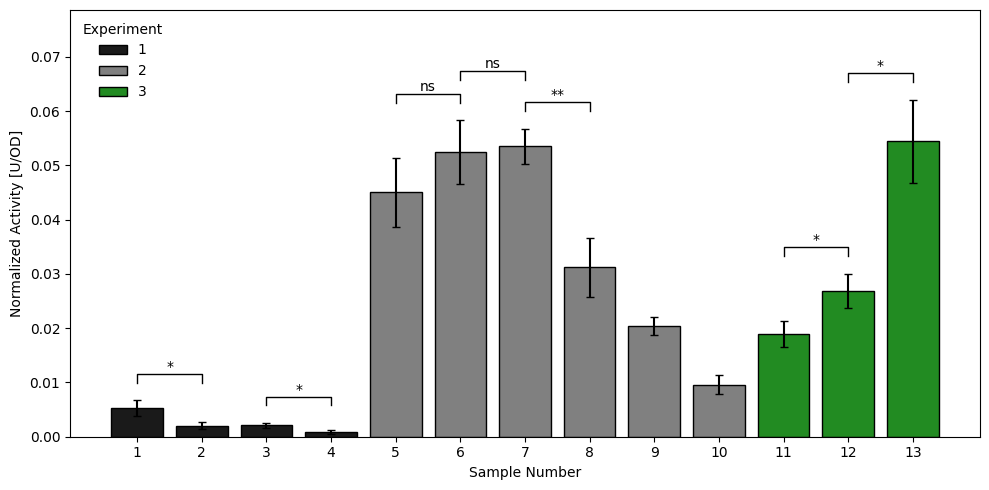

In [ ]:
# plots
def p_to_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def add_sig_bracket(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], linewidth=1, color='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=10)

def make_plot_df(summary_0126, summary_040226, final_110226):
    # Add labels that match how the test functions named groups:
    # 0126: 0126_g0, 0126_g1, ...
    df_0126 = summary_0126.copy()
    df_0126["dataset"] = "0126"
    df_0126["group"] = np.arange(len(df_0126))
    df_0126["label"] = df_0126["group"].map(lambda i: f"0126_g{i}")

    # 040226: 040226_g0, 040226_g1, ...
    df_040 = summary_040226.copy()
    df_040["dataset"] = "040226"
    df_040["group"] = np.arange(len(df_040))
    df_040["label"] = df_040["group"].map(lambda i: f"040226_g{i}")

    # 110226 final meta groups: 110226_M0, 110226_M1, 110226_M2
    df_110 = final_110226.copy()
    df_110["dataset"] = "110226"
    df_110["group"] = np.arange(len(df_110))
    df_110["label"] = df_110["group"].map(lambda i: f"110226_M{i}")

    plot_df = pd.concat([df_0126, df_040, df_110], ignore_index=True)

    # keep only what's needed
    plot_df = plot_df[["dataset", "group", "label", "mean", "std", "n"]].copy()
    return plot_df

def plot_bars_with_significance(plot_df, tests_dfs, title="Grouped means ± SD"):
    """
    plot_df columns: dataset, label, mean, std
    tests_dfs: list of test dfs each with columns A, B, p
              where A/B values correspond to plot_df['label'].
    """
    # Assign x positions sequentially
    plot_df = plot_df.copy()
    plot_df["x"] = np.arange(len(plot_df))

    # Colors per dataset
    datasets = plot_df["dataset"].unique()
    
    # define colours
    ds_to_color = {
        "0126": "0.1",
        "040226": "0.5",
        "110226": "forestgreen",
    }

    # costum legend
    ds_to_legend = {
    "0126": "1",
    "040226": "2",
    "110226": "3"}

    fig, ax = plt.subplots(figsize=(max(10, len(plot_df) * 0.5), 5))

    # Plot bars dataset-by-dataset (so legend works cleanly)
    for ds in datasets:
        sub = plot_df[plot_df["dataset"] == ds]
        ax.bar(
            sub["x"].values,
            sub["mean"].values,
            yerr=sub["std"].values,
            capsize=3,
            label=ds_to_legend[ds],
            color=ds_to_color[ds],
            edgecolor="black",
            linewidth=1
        )

    # X tick labels
    ax.set_xticks(plot_df["x"].values)

    # number labels 1 → N
    numbers = np.arange(1, len(plot_df) + 1)
    ax.set_xticklabels(numbers)

    ax.set_xlabel('Sample Number')
    ax.set_ylabel("Normalized Activity [U/OD]")
    ax.legend(title="Experiment", frameon=False)

    # Map label -> x, and label -> bar top (mean + std) to place brackets above
    label_to_x = dict(zip(plot_df["label"], plot_df["x"]))
    label_to_top = dict(zip(plot_df["label"], plot_df["mean"] + plot_df["std"].fillna(0)))

    # Combine tests, keep only those that map to visible labels
    all_tests = pd.concat(tests_dfs, ignore_index=True)
    all_tests = all_tests[all_tests["A"].isin(label_to_x) & all_tests["B"].isin(label_to_x)].copy()

    # Add stars and only keep significant ones
    all_tests["stars"] = all_tests["p"].apply(p_to_stars)

    # Sort by p so the strongest effects get placed first
    all_tests = all_tests.sort_values("p", ascending=True)

    # Bracket placement:
    # - base height above the taller of the two bars
    # - stack brackets by increasing y to avoid overlap
    if len(all_tests) > 0:
        y_range = (plot_df["mean"].max() - plot_df["mean"].min()) or 1.0
        h = 0.03 * y_range  # bracket height
        pad = 0.06 * y_range  # vertical padding above bars
        step = 0.08 * y_range  # stacking step between brackets

        # Track used "levels" per x-span to reduce collisions
        used_levels = []

        for _, row in all_tests.iterrows():
            a, b, p, stars = row["A"], row["B"], row["p"], row["stars"]
            x1, x2 = label_to_x[a], label_to_x[b]
            if x1 == x2:
                continue
            if x2 < x1:
                x1, x2 = x2, x1

            base = max(label_to_top[a], label_to_top[b]) + pad

            # choose stacking level
            level = 0
            while True:
                y = base + level * step
                span = (x1, x2, y)
                # overlap test: avoid same y with overlapping x spans
                collision = any(
                    (abs(y - yy) < 1e-9) and not (x2 < xx1 or x1 > xx2)
                    for (xx1, xx2, yy) in used_levels
                )
                if not collision:
                    used_levels.append((x1, x2, y))
                    break
                level += 1

            add_sig_bracket(ax, x1, x2, y, h, stars)

        # Expand ylim so brackets fit
        ax.set_ylim(top=max(ax.get_ylim()[1], max(yy for *_, yy in used_levels) + 3 * step))

    plt.tight_layout()
    return fig, ax

# ---- usage ----
plot_df = make_plot_df(summary_0126, summary_040226, final_110226)

fig, ax = plot_bars_with_significance(
    plot_df,
    tests_dfs=[tests_0126, tests_040226, tests_110226_final],
    title="Activity at different Lysis Settings"
)
#plt.savefig("lysis_optimization.png", dpi=300, bbox_inches="tight")
plt.show()